## ConvNeXtTiny model 을 가지고 항목 분류 학습 진행
학습할 이미지 업로드하여 ./labeled 디렉토리에 넣어서 진행

produce, sea_food, meat, grain, etc

In [1]:
import tensorflow as tf
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight

from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import ConvNeXtTiny
from tensorflow.keras import layers, models
import matplotlib.pyplot as plt

In [2]:
!apt-get update -qq
!apt-get install -y fonts-nanum

!fc-list | grep -i "Nanum"

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
The following NEW packages will be installed:
  fonts-nanum
0 upgraded, 1 newly installed, 0 to remove and 95 not upgraded.
Need to get 10.3 MB of archives.
After this operation, 34.1 MB of additional disk space will be used.
Get:1 http://archive.ubuntu.com/ubuntu noble/universe amd64 fonts-nanum all 20200506-1 [10.3 MB]
Fetched 10.3 MB in 2s (5,309 kB/s)
Selecting previously unselected package fonts-nanum.
(Reading database ... 127324 files and directories currently installed.)
Preparing to unpack .../fonts-nanum_20200506-1_all.deb ...
Unpacking fonts-nanum (20200506-1) ...
Setting up fonts-nanum (20200506-1) ...
Processing triggers for fontconfig (2.15.0-1.1ubuntu2) ...
/usr/share/fonts/truetype/nanum/N

In [3]:
import os

font_path = "/usr/share/fonts/truetype/nanum/NanumGothic.ttf"

print("파일 존재 여부:", os.path.exists(font_path))

파일 존재 여부: True


적용 폰트: NanumGothic


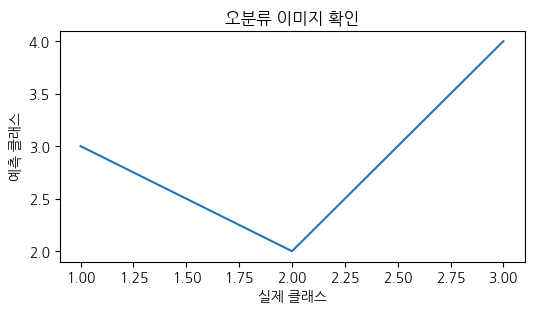

In [4]:
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm

# 폰트 캐시 삭제
!rm -rf ~/.cache/matplotlib

# 폰트 등록
fm.fontManager.addfont(font_path)

# 폰트 설정
font_name = fm.FontProperties(fname=font_path).get_name()

mpl.rcParams["font.family"] = font_name
mpl.rcParams["axes.unicode_minus"] = False

print("적용 폰트:", font_name)

plt.figure(figsize=(6, 3))
plt.title("오분류 이미지 확인")
plt.xlabel("실제 클래스")
plt.ylabel("예측 클래스")
plt.plot([1, 2, 3], [3, 2, 4])
plt.show()

In [11]:
# ============================================================
# [이 셀에서 하는 일] 다운로드 결과 확인
# ------------------------------------------------------------
# 파일이 작업 폴더에 정상적으로 내려받아졌는지, 크기가 0이 아닌지
# 확인합니다. (-l 옵션: 크기·날짜까지 자세히 보기)
# ============================================================

!ls -l    # 현재 폴더의 파일 목록 (-l: 크기·날짜까지 자세히)

total 49700
-rw-r--r-- 1 root root 50882940 Nov 17 06:35 5item_labeled.zip
drwxr-xr-x 7 root root     4096 Nov 17 06:35 labeled
drwxr-xr-x 1 root root     4096 Nov 13 15:50 sample_data


In [10]:
# ============================================================
# [이 셀에서 하는 일] 압축 풀기
# ------------------------------------------------------------
# 압축을 풀면 train / validation / test 폴더가
# 생기고, 그 안에 클래스별 하위 폴더가 있습니다. 이미지 분류에서는 보통
# "폴더 이름 = 정답(클래스)" 규칙으로 데이터를 정리합니다.
# ============================================================

!unzip -q /content/5item_labeled.zip -d /content/labeled   # 압축 풀기 (-q: 진행 메시지 생략)

In [12]:
# 기본 설정
DATA_DIR = "./labeled"
IMAGE_SIZE = (224, 224)
BATCH_SIZE = 16
SEED = 42

# 원하는 클래스 순서
# produce, sea_food, meat, grain, processed_food, etc
CLASS_NAMES = [
    "produce",
    "sea_food",
    "meat",
    "grain",
    #"processed_food",
    "etc"
]

CLASS_SIZE = len(CLASS_NAMES)


In [13]:
len(CLASS_NAMES)

5

In [14]:


# 이미지 데이터 로드
datagen = ImageDataGenerator()

# 6가지 item 구분
data = datagen.flow_from_directory(
    DATA_DIR,
    classes=CLASS_NAMES,
    target_size=IMAGE_SIZE,
    batch_size=1,
    class_mode="sparse",
    shuffle=False
)

X = []
y = []

for i in range(len(data)):
    img, label = data[i]

    X.append(img[0])
    y.append(int(label[0]))

X = np.array(X)
y = np.array(y)

print("전체 이미지:", len(X))
print("클래스 매핑:", data.class_indices)

# Train / 나머지 분리
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.3,
    random_state=SEED,
    stratify=y
)

# Validation / Test 분리
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.5,
    random_state=SEED,
    stratify=y_temp
)

print("Train:", len(X_train))
print("Validation:", len(X_val))
print("Test:", len(X_test))

# 클래스별 Label 확인
print("\n클래스별 Label:")
for name, index in data.class_indices.items():
    print(f"{index}: {name}")

# 클래스별 데이터 개수 확인
print("\n클래스별 데이터 분포:")
for name, index in data.class_indices.items():
    print(
        f"{name}: "
        f"Train={np.sum(y_train == index)}, "
        f"Validation={np.sum(y_val == index)}, "
        f"Test={np.sum(y_test == index)}"
    )

Found 1199 images belonging to 5 classes.
전체 이미지: 1199
클래스 매핑: {'produce': 0, 'sea_food': 1, 'meat': 2, 'grain': 3, 'etc': 4}
Train: 839
Validation: 180
Test: 180

클래스별 Label:
0: produce
1: sea_food
2: meat
3: grain
4: etc

클래스별 데이터 분포:
produce: Train=283, Validation=61, Test=61
sea_food: Train=125, Validation=26, Test=27
meat: Train=157, Validation=34, Test=33
grain: Train=152, Validation=32, Test=33
etc: Train=122, Validation=27, Test=26


In [15]:

# Train / Validation / Test 분리 후
X_test_raw = X_test.copy()


In [17]:
# 데이터 증강
data_augmentation = models.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.05),
    layers.RandomZoom(0.1),
    layers.RandomTranslation(0.05, 0.05),
])

# 사전학습 모델
base_model = ConvNeXtTiny(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

base_model.trainable = False

# 분류 모델 구성
inputs = layers.Input(shape=(224, 224, 3))

x = data_augmentation(inputs)
x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dense(256, activation="relu")(x)
x = layers.Dropout(0.5)(x)

outputs = layers.Dense(
    CLASS_SIZE,
    activation="softmax"
)(x)

model = models.Model(inputs, outputs)

X_train = X_train.astype("float32")
X_val = X_val.astype("float32")
X_test = X_test.astype("float32")

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# 클래스 불균형 보정
class_weights = compute_class_weight(
    class_weight="balanced",
    classes=np.unique(y_train),
    y=y_train
)

class_weight_dict = {
    i: weight for i, weight in enumerate(class_weights)
}

model.summary()


Model: "functional_10"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_12 (InputLayer)     │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential_1 (Sequential)       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ convnext_tiny (Functional)      │ (None, 7, 7, 768)      │    27,820,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 768)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 256)            │       196,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 5)              │         1,285 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 28,018,277 (106.88 MB)

 Trainable params: 198,149 (774.02 KB)

 Non-trainable params: 27,820,128 (106.13 MB)

In [18]:

# 학습
# history = model.fit(
#     X_train,
#     y_train,
#     validation_data=(X_val, y_val),
#     epochs=20,
#     batch_size=BATCH_SIZE,
#     class_weight=class_weight_dict
# )

early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

history = model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=40,
    batch_size=BATCH_SIZE,
    class_weight=class_weight_dict,
    callbacks=[early_stopping]
)

print("실제 학습 Epoch:", len(history.history["loss"]))
print("최고 Validation Accuracy:",
      max(history.history["val_accuracy"]))
print("최저 Validation Loss:",
      min(history.history["val_loss"]))


Epoch 1/40
53/53 ━━━━━━━━━━━━━━━━━━━━ 43s 409ms/step - accuracy: 0.3123 - loss: 1.5956 - val_accuracy: 0.5833 - val_loss: 1.2523
Epoch 2/40
53/53 ━━━━━━━━━━━━━━━━━━━━ 10s 182ms/step - accuracy: 0.5232 - loss: 1.2641 - val_accuracy: 0.6556 - val_loss: 1.0473
Epoch 3/40
53/53 ━━━━━━━━━━━━━━━━━━━━ 10s 184ms/step - accuracy: 0.6126 - loss: 1.0989 - val_accuracy: 0.7222 - val_loss: 0.9242
Epoch 4/40
53/53 ━━━━━━━━━━━━━━━━━━━━ 10s 189ms/step - accuracy: 0.6687 - loss: 0.9791 - val_accuracy: 0.7556 - val_loss: 0.8353
Epoch 5/40
53/53 ━━━━━━━━━━━━━━━━━━━━ 10s 187ms/step - accuracy: 0.7139 - loss: 0.8604 - val_accuracy: 0.7833 - val_loss: 0.7705
Epoch 6/40
53/53 ━━━━━━━━━━━━━━━━━━━━ 10s 190ms/step - accuracy: 0.7545 - loss: 0.7853 - val_accuracy: 0.7833 - val_loss: 0.7252
Epoch 7/40
53/53 ━━━━━━━━━━━━━━━━━━━━ 10s 193ms/step - accuracy: 0.7795 - loss: 0.7073 - val_accuracy: 0.7944 - val_loss: 0.6836
Epoch 8/40
53/53 ━━━━━━━━━━━━━━━━━━━━ 21s 195ms/step - accuracy: 0.7914 - loss: 0.6734 - val_accu

In [19]:

# 모델 저장
model.save("ConvNeXtTiny_5item_classifier.keras")


In [ ]:
#print(history.history["loss"])
for key in history.history:
  print(key)
  for index in history.history[key]:
    print(index)


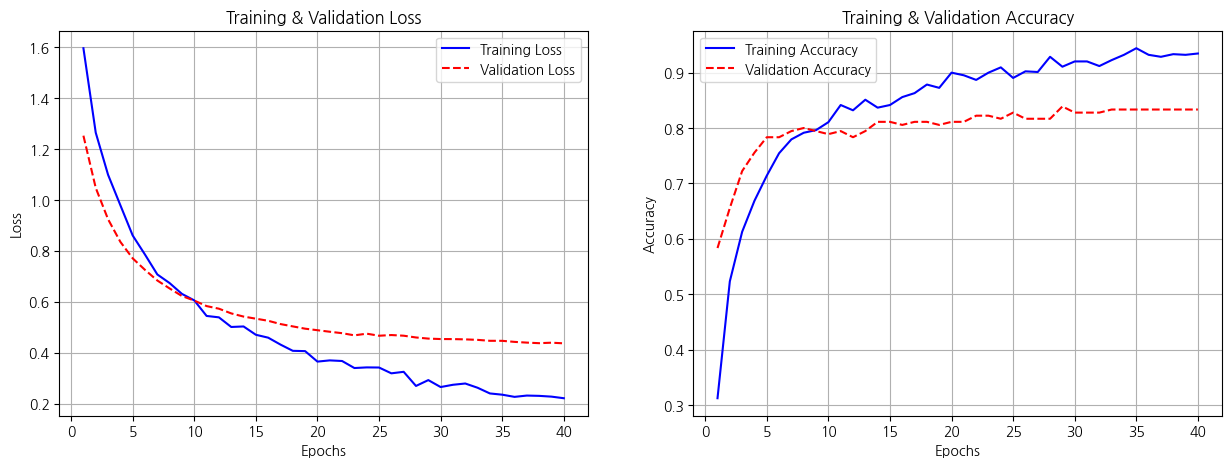

In [20]:

# fit()이 돌려준 history에는 epoch마다 기록된 loss, accuracy, val_loss, val_accuracy가 들어 있습니다.
epochs = range(1, len(history.history['loss']) + 1)    # x축 값: 1, 2, 3, ... (epoch 번호)

plt.figure(figsize = (15, 5))    # 가로 15 × 세로 5 크기의 그림판 준비

plt.subplot(1, 2, 1)    # 1행 2열 중 왼쪽 그래프: 손실(Loss)
plt.plot(epochs, history.history['loss'], 'b-')    # 파란 실선: 훈련 데이터 기록
plt.plot(epochs, history.history['val_loss'], 'r--')    # 빨간 점선: 검증 데이터 기록
plt.title('Training & Validation Loss')    # 그래프 제목
plt.xlabel('Epochs')    # x축: 학습 반복 횟수
plt.ylabel('Loss')    # y축: 손실(작을수록 좋음)
plt.legend(['Training Loss', 'Validation Loss'])    # 범례(선 이름표) 표시
plt.grid()    # 격자 표시

plt.subplot(1, 2, 2)    # 1행 2열 중 오른쪽 그래프: 정확도(Accuracy)
plt.plot(epochs, history.history['accuracy'], 'b-')    # 파란 실선: 훈련 데이터 기록
plt.plot(epochs, history.history['val_accuracy'], 'r--')    # 빨간 점선: 검증 데이터 기록
plt.title('Training & Validation Accuracy')    # 그래프 제목
plt.xlabel('Epochs')    # x축: 학습 반복 횟수
plt.ylabel('Accuracy')    # y축: 정확도(클수록 좋음)
plt.legend(['Training Accuracy', 'Validation Accuracy'])    # 범례(선 이름표) 표시
plt.grid()    # 격자 표시

plt.show()    # 그래프 화면에 출력

In [21]:
test_loss, test_accuracy = model.evaluate(
    X_test,
    y_test,
    verbose=1
)

print("Test Accuracy:", test_accuracy)
print("Test Loss:", test_loss)

6/6 ━━━━━━━━━━━━━━━━━━━━ 10s 1s/step - accuracy: 0.8111 - loss: 0.5034
Test Accuracy: 0.8111110925674438
Test Loss: 0.5034359693527222


In [22]:
from sklearn.metrics import classification_report

y_pred = np.argmax(model.predict(X_test), axis=1)

print(classification_report(
    y_test,
    y_pred,
    target_names=CLASS_NAMES
))

6/6 ━━━━━━━━━━━━━━━━━━━━ 14s 2s/step
              precision    recall  f1-score   support

     produce       0.92      0.89      0.90        61
    sea_food       0.61      0.74      0.67        27
        meat       0.87      0.79      0.83        33
       grain       0.85      0.85      0.85        33
         etc       0.72      0.69      0.71        26

    accuracy                           0.81       180
   macro avg       0.79      0.79      0.79       180
weighted avg       0.82      0.81      0.81       180



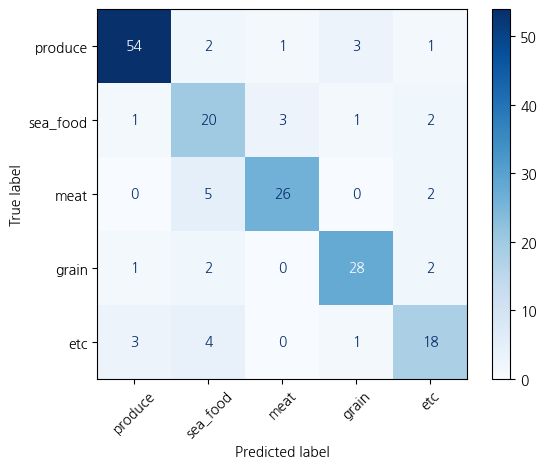

In [23]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=CLASS_NAMES
)

disp.plot(cmap="Blues", xticks_rotation=45)
plt.show()

In [24]:
from sklearn.metrics import confusion_matrix
import pandas as pd

cm = confusion_matrix(y_test, y_pred)

cm_df = pd.DataFrame(
    cm,
    index=[f"실제_{name}" for name in CLASS_NAMES],
    columns=[f"예측_{name}" for name in CLASS_NAMES]
)

print(cm_df)

             예측_produce  예측_sea_food  예측_meat  예측_grain  예측_etc
실제_produce           54            2        1         3       1
실제_sea_food           1           20        3         1       2
실제_meat               0            5       26         0       2
실제_grain              1            2        0        28       2
실제_etc                3            4        0         1      18


In [25]:
# 예측 실패 확인하기

import numpy as np
import matplotlib.pyplot as plt

# 예측 확률
y_prob = model.predict(X_test)

# 예측 클래스
y_pred = np.argmax(y_prob, axis=1)

# 오분류된 이미지 인덱스
wrong_indices = np.where(y_test != y_pred)[0]

print("전체 Test 이미지:", len(y_test))
print("오분류 이미지:", len(wrong_indices))

# 이미지 출력
cols = 4
rows = int(np.ceil(len(wrong_indices) / cols))

plt.figure(figsize=(16, rows * 4))

for i, idx in enumerate(wrong_indices):
    plt.subplot(rows, cols, i + 1)

    # 원본 이미지 출력 (VGG16 전처리 전 이미지 필요)
    plt.imshow(X_test_raw[idx].astype("uint8"))

    actual = CLASS_NAMES[y_test[idx]]
    predicted = CLASS_NAMES[y_pred[idx]]
    confidence = y_prob[idx][y_pred[idx]] * 100

    plt.title(
        f"실제: {actual}\n"
        f"예측: {predicted} ({confidence:.1f}%)",
        color="red"
    )

    plt.axis("off")

plt.tight_layout()
plt.show()

Output hidden; open in https://colab.research.google.com to view.